In [26]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
col_dict = {0: 'orange', 1: 'lime', 2: 'purple', 3: 'red', 4:'yellow', 5:'black', 6:'green', 7:'pink', 8:'blue',9:'lime', 10:'sienna',11:'indigo'}

## First scenario

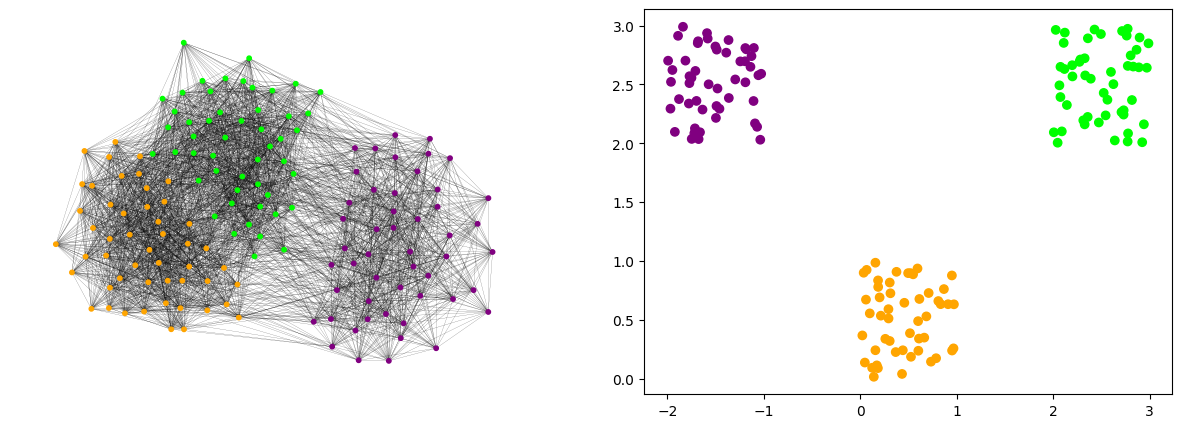

In [27]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
nx.draw(G, ax= ax0, node_size=10, width=0.1,node_color=dtemp['label'])
#ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

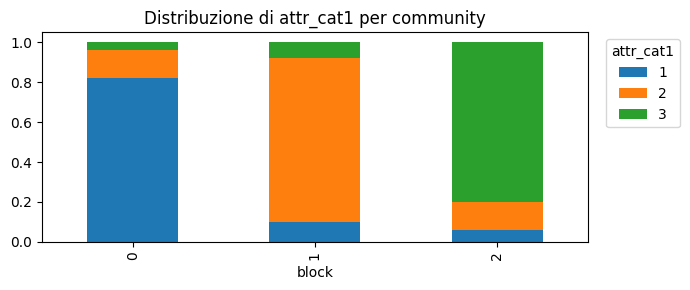

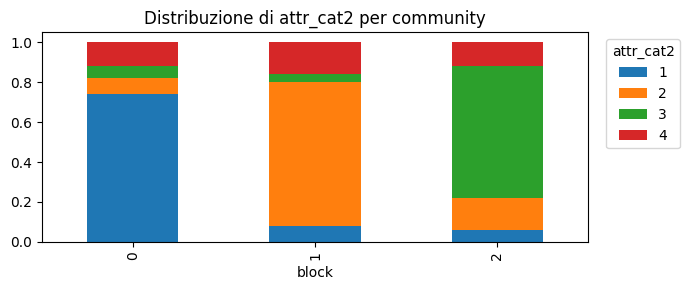

In [19]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [20]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [21]:
for K in Ks:
    print(Rs[K]['vICL'])

-6151.921109964291
-5714.980896212998
-5759.872638351495
-5784.123283272567


In [23]:
Rs[3]['Sigma_list']

[array([[0.09226868, 0.00206404],
        [0.00206404, 0.09365852]]),
 array([[0.08675904, 0.00407937],
        [0.00407937, 0.07681261]]),
 array([[0.08178443, 0.00306605],
        [0.00306605, 0.0825881 ]])]

In [6]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

In [25]:
Rs[3]['phi_list']

[array([[0.1 , 0.82, 0.08],
        [0.06, 0.14, 0.8 ],
        [0.82, 0.14, 0.04]]),
 array([[0.08, 0.72, 0.04, 0.16],
        [0.06, 0.16, 0.66, 0.12],
        [0.74, 0.08, 0.06, 0.12]])]

### ILouvain con Gower - first

In [ ]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [28]:
ARI(list(partition_ilouv.values()), labels)

1.0

### SA cluster first

In [9]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.6565


### STOC cluster first

In [10]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=7  ARI=0.8183


## Second scenario

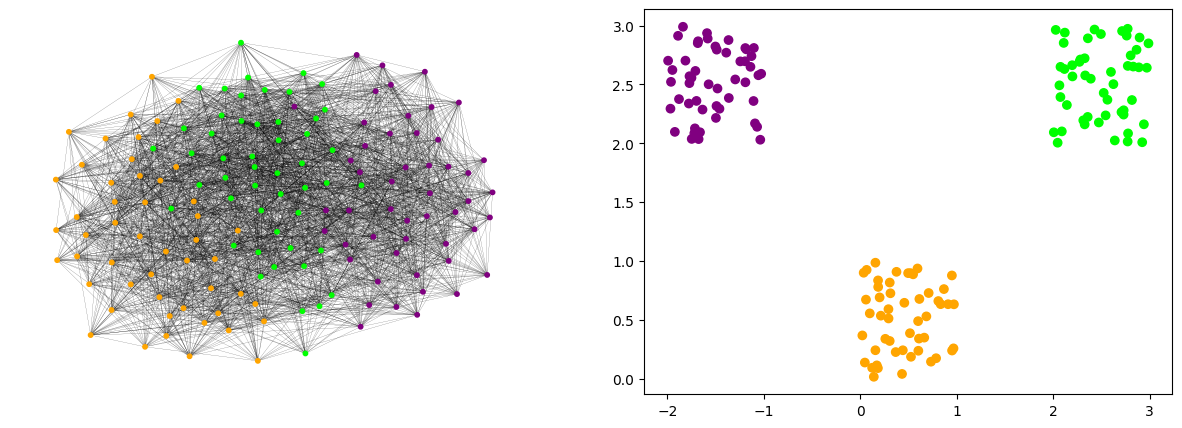

In [28]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.4, 0.2, 0.1],[0.2,0.4,0.2],[0.1,0.2,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
nx.draw(G, ax= ax0, node_size=10, width=0.1,node_color=dtemp['label'])
#ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

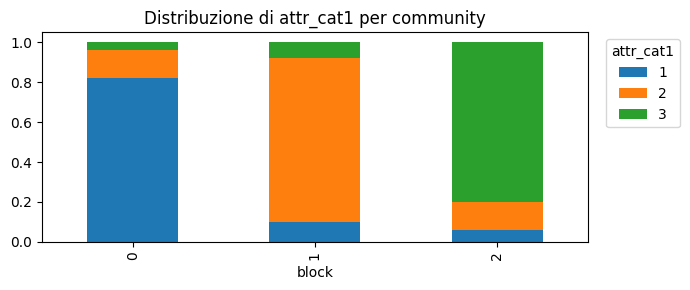

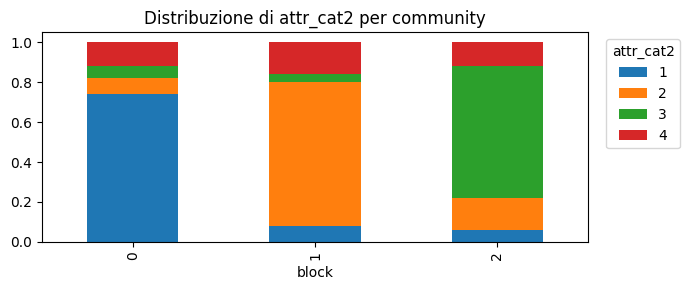

In [30]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [31]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [14]:
for k in Rs.keys():
    print(Rs[k]['vICL'])

-6678.745833587969
-6416.489664924734
-6457.2783487758825
-6493.60144039971


In [120]:
pd.DataFrame(Rs[3]['r'])

,0,1,2
0,2.552745e-22,3.299459e-32,1.000000e+00
1,1.042146e-26,1.228439e-48,1.000000e+00
2,6.887166e-24,1.996936e-42,1.000000e+00
3,4.494118e-26,3.821951e-38,1.000000e+00
4,1.087383e-23,1.945380e-26,1.000000e+00
...,...,...,...
145,8.902243e-52,1.000000e+00,4.726372e-40
146,1.405724e-45,1.000000e+00,2.296780e-37
147,1.357016e-44,1.000000e+00,1.942127e-32
148,2.425166e-52,1.000000e+00,2.015216e-42


In [36]:
Rs[3]['mu_list']

[array([2.49443758, 2.51605093]),
 array([-1.52170008,  2.51915173]),
 array([0.4459239 , 0.51736353])]

In [33]:
Rs[3]['phi_list']

[array([[0.1 , 0.82, 0.08],
        [0.06, 0.14, 0.8 ],
        [0.82, 0.14, 0.04]]),
 array([[0.08, 0.72, 0.04, 0.16],
        [0.06, 0.16, 0.66, 0.12],
        [0.74, 0.08, 0.06, 0.12]])]

In [34]:
Rs[3]['Theta']

array([[0.40653061, 0.206     , 0.2128    ],
       [0.206     , 0.41714286, 0.1024    ],
       [0.2128    , 0.1024    , 0.38530612]])

In [ ]:
probs = [[0.4, 0.2, 0.1],
         [0.2,0.4,0.2],
         [0.1,0.2,0.4]]

In [37]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels)

1.0

### ILouvain con Gower - second

In [16]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [17]:
ARI(list(partition_ilouv.values()), labels)

0.5228988572603626

### SA cluster second

In [135]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=-0.0052


### STOC cluster second

In [144]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=7  ARI=0.8183


# Third scenario

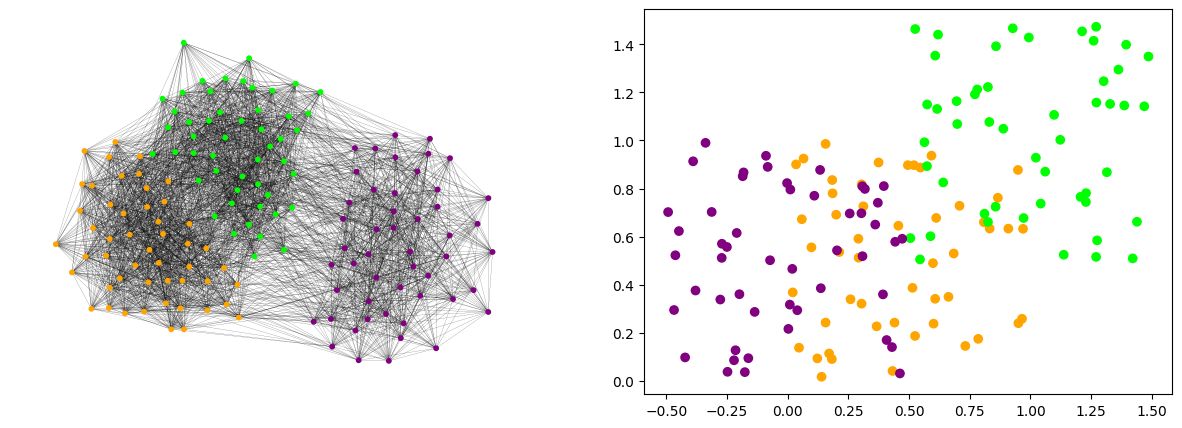

In [29]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+0.5
Xg[100:,0]=np.random.random_sample(50)-0.5

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+0.5
Xg[100:,1]=np.random.random_sample(50)
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
nx.draw(G, ax= ax0, node_size=10, width=0.1,node_color=dtemp['label'])
#ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

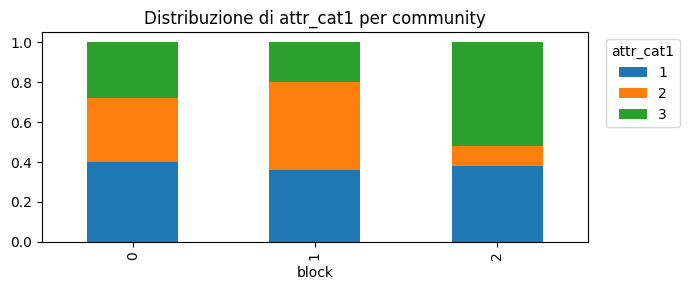

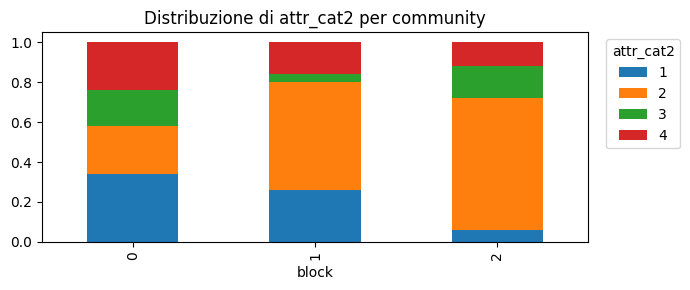

In [41]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.33,0.33,0.34])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.5,0.15])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.15,0.5])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.25,0.25,0.25])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.6,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.7,0.15,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [42]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [43]:
for k in Rs.keys():
    print(Rs[k]['vICL'])

-6089.244731867563
-5817.425035589147
-5853.514533103006
-5885.293912198168


In [112]:
pd.DataFrame(Rs[3]['r'])

,0,1,2
0,2.538896e-06,2.056613e-15,9.999975e-01
1,1.534077e-09,2.892246e-17,1.000000e+00
2,9.139916e-04,1.932708e-11,9.990860e-01
3,2.662640e-08,1.093485e-12,1.000000e+00
4,5.659537e-06,5.436695e-11,9.999943e-01
...,...,...,...
145,1.049447e-08,1.000000e+00,4.261786e-13
146,2.845845e-10,1.000000e+00,1.150248e-12
147,7.419089e-10,1.000000e+00,5.160866e-14
148,5.288160e-11,1.000000e+00,4.099340e-15


In [45]:
Rs[3]['mu_list']

[array([0.99443623, 1.01605   ]),
 array([-0.02170008,  0.51915173]),
 array([0.44592387, 0.51736321])]

In [46]:
Rs[3]['Theta']

array([[0.50122294, 0.1016002 , 0.21280047],
       [0.1016002 , 0.50530612, 0.05359968],
       [0.21280047, 0.05359968, 0.58775611]])

In [ ]:
probs = [[0.6, 0.2, 0.05],
         [0.2,0.5,0.1],
         [0.05,0.1,0.5]]


In [44]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels)

1.0

### ILouvain con Gower - third

In [47]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [48]:
ARI(list(partition_ilouv.values()), labels)

1.0

### SA cluster third

In [138]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0271


### STOC cluster third

In [147]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.3878
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=11  ARI=0.2283


## Fourth scenario

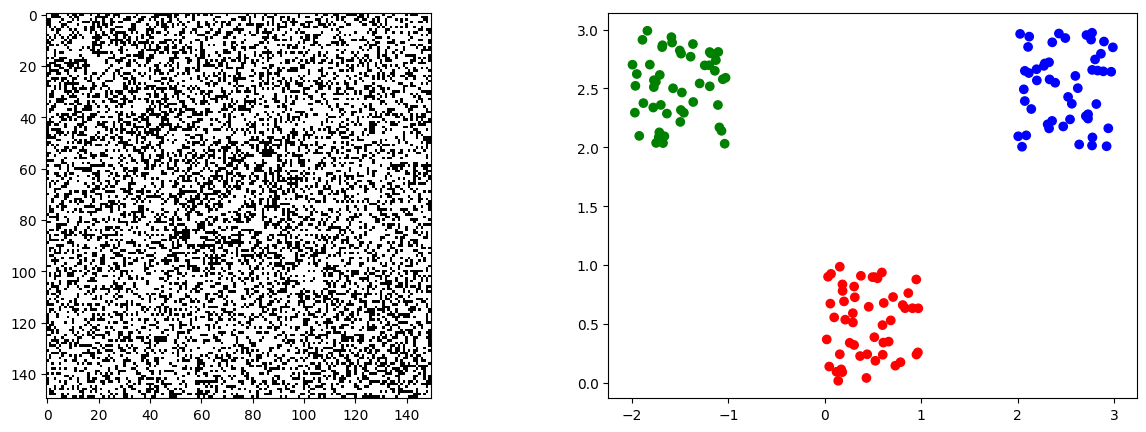

In [49]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.4, 0.3, 0.3],[0.3,0.4,0.3],[0.3,0.3,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

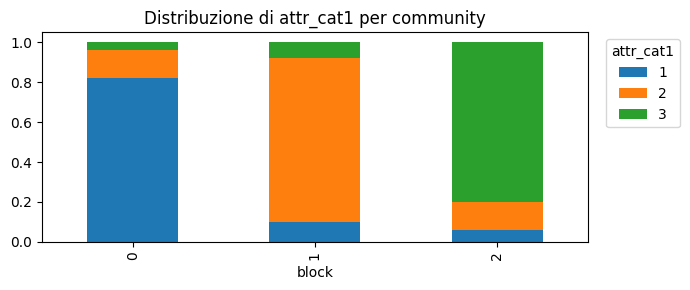

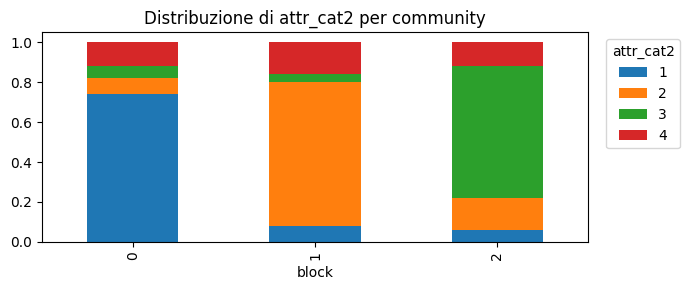

In [50]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [51]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [52]:
for K in Ks:
    print(Rs[K]['vICL'])

-7741.649757943619
-7591.971419243181
-7624.174569423979
-7666.684826878228


In [54]:
Rs[3]['Theta']

array([[0.40653061, 0.2872    , 0.316     ],
       [0.2872    , 0.38122449, 0.2996    ],
       [0.316     , 0.2996    , 0.38530612]])

In [55]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

### ILouvain con Gower - fourth

In [56]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [57]:
ARI(list(partition_ilouv.values()), labels)

0.0

### SA cluster fourth

In [156]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0133


### STOC cluster fourth

In [157]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=8  ARI=0.8175
